<a href="https://colab.research.google.com/github/CasualMathEnjoyer/01NAEX/blob/main/HW/01NAEX_Ex05_HW_Morovicsova.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01NAEX - Exercise 05: The $2^k$ factorial design

Data and exercises come from D. C. Montgomery: *Design and Analysis of Experiments*, 8th edition, Chapter 6.
Problem numbers follow the 8th edition.

## Learning goals

* Estimate the effects of a $2^k$ design from the table of plus and minus signs and relate them to the ANOVA and to the
  regression coefficients in coded variables (effect $= 2\hat\beta$).
* Fit the full model, refine it, test the lack of fit of the reduced model against the pure error and respect the hierarchy principle.
* Convert the model between coded and natural variables and draw response surface, contour and interaction plots.
* Compute standard errors and confidence intervals of the effects and use them to plan the number of replicates.
* Generate a randomized $2^k$ design in Python.

**Homework: Katka Morovicsova**

## Setup

Run this cell first. Besides the standard imports it defines helper functions used below:

* `effects_2k()` - contrasts, effects, sums of squares and coded coefficients of a balanced (replicated) $2^k$ design, computed
  directly from the table of signs.
* `design_2k()` - a $2^k$ design in standard (Yates) order with $n$ replicates and a random run order.
* `residual_plots()` - normal Q-Q plot of the residuals, residuals versus fitted values and versus each factor, Shapiro-Wilk test.

In [1]:
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.graphics.factorplots import interaction_plot

from pathlib import Path
from IPython.display import display

# Prefer repository data; the URL also supports standalone use in Colab.
data_dir = next((p for p in [Path("../data"), Path("data")] if (p / "Problem_6_1.txt").exists()), None)
URL = str(data_dir) + "/" if data_dir is not None else "https://raw.githubusercontent.com/francji1/01NAEX/main/data/"


def effects_2k(data, response, factors):
    """Contrasts, effects, sums of squares and coded coefficients of a balanced 2^k design.

    `factors` are columns coded -1/+1 (main effects in this order: A, B, C, ...). Rows are in standard order
    (A, B, AB, C, AC, BC, ABC, ...) and are named as in statsmodels formulas ("A:B").
    """
    k = len(factors)
    n = len(data) // 2**k
    rows = []
    for i in range(1, 2**k):
        members = [factors[j] for j in range(k) if i >> j & 1]
        sign = data[members].prod(axis=1)
        contrast = (sign * data[response]).sum()
        rows.append({"term": ":".join(members), "contrast": contrast,
                     "effect": contrast / (n * 2**(k - 1)), "SS": contrast**2 / (n * 2**k)})
    table = pd.DataFrame(rows).set_index("term")
    table["coef"] = table["effect"] / 2
    return table


def design_2k(k, n_rep=1, names="ABCDEFGH", seed=None):
    """2^k factorial design in standard order, n_rep replicates and a random run order (column `run`)."""
    runs = itertools.product([-1, 1], repeat=k)
    std = pd.DataFrame([r[::-1] for r in runs], columns=list(names[:k]))      # the first factor changes fastest
    design = pd.concat([std] * n_rep, ignore_index=True)
    design.insert(0, "std_order", np.tile(np.arange(1, 2**k + 1), n_rep))
    design["rep"] = np.repeat(np.arange(1, n_rep + 1), 2**k)
    rng = np.random.default_rng(seed)
    design["run"] = rng.permutation(len(design)) + 1
    return design


def residual_plots(model, data, factors):
    """Q-Q plot, residuals vs fitted values and vs each factor; Shapiro-Wilk test of the residuals."""
    res, fit = model.resid, model.fittedvalues
    fig, axes = plt.subplots(1, 2 + len(factors), figsize=(3.6 * (2 + len(factors)), 3.3))
    sm.qqplot(res, line="s", ax=axes[0])
    axes[0].set_title("Normal Q-Q plot")
    axes[1].scatter(fit, res)
    axes[1].axhline(0, color="red", ls="--")
    axes[1].set(xlabel="fitted", ylabel="residual", title="Residuals vs fitted")
    for ax, f in zip(axes[2:], factors):
        ax.scatter(data[f], res)
        ax.axhline(0, color="red", ls="--")
        ax.set(xlabel=f, title=f"Residuals vs {f}")
    plt.tight_layout()
    plt.show()
    print("Shapiro-Wilk on residuals:", stats.shapiro(res))


def test_table(model):
    """Each row tests H0: the named effect is zero, versus H1: nonzero."""
    table = sm.stats.anova_lm(model, typ=2)
    table["decision (alpha=.05)"] = [
        "Reject H0" if p < .05 else "Do not reject H0" if np.isfinite(p) else ""
        for p in table["PR(>F)"]]
    display(table)
    print(f"Error df = {model.df_resid:g}; MSE = {model.mse_resid:.6f}")
    return table


## 1. Lecture example: chemical process ($2^2$ design)

Montgomery, Section 6.2: the effect of the reactant concentration (factor $A$: 15 and 25 %) and of the amount of catalyst
(factor $B$: 1 and 2 pounds) on the yield of a chemical process; $n = 3$ replicates, 12 runs in random order.

`yield` is a Python keyword, so a formula `yield ~ ...` does not work. We rename the column to `y`
(the alternative is to quote it in the formula: `Q("yield") ~ ...`).

In [2]:
chem = pd.read_csv(URL + "yield.txt", sep=r"\s+").rename(columns={"yield": "y"})
chem["A"] = chem["reactant"].map({"low": -1, "high": 1})
chem["B"] = chem["catalyst"].map({"low": -1, "high": 1})

# treatment totals (1), a, b, ab
totals = chem.groupby(["B", "A"])["y"].sum()
totals.index = ["(1)", "a", "b", "ab"]
print(totals)
chem.pivot_table(index="catalyst", columns="reactant", values="y", aggfunc=list)

(1)     80
a      100
b       60
ab      90
Name: y, dtype: int64


reactant,high,low
catalyst,,
high,"[31, 30, 29]","[18, 19, 23]"
low,"[36, 32, 32]","[28, 25, 27]"


### Effects from the treatment totals

$A = \frac{1}{2n}[ab + a - b - (1)]$, $B = \frac{1}{2n}[ab + b - a - (1)]$, $AB = \frac{1}{2n}[ab + (1) - a - b]$,
$SS = \text{Contrast}^2 / (4n)$.

In [3]:
one, a, b, ab = totals
n = 3
contrasts = {"A": ab + a - b - one, "B": ab + b - a - one, "A:B": ab + one - a - b}
for name, c in contrasts.items():
    print(f"{name:4s} contrast = {c:4d}, effect = {c / (2 * n):6.3f}, SS = {c**2 / (4 * n):7.3f}")

# the same with the helper function (works for any k)
effects_2k(chem, "y", ["A", "B"])

A    contrast =   50, effect =  8.333, SS = 208.333
B    contrast =  -30, effect = -5.000, SS =  75.000
A:B  contrast =   10, effect =  1.667, SS =   8.333


,contrast,effect,SS,coef
term,,,,
A,50,8.333333,208.333333,4.166667
B,-30,-5.000000,75.000000,-2.500000
A:B,10,1.666667,8.333333,0.833333


### ANOVA and model refinement

In [4]:
m_full = smf.ols("y ~ A * B", data=chem).fit()
display(sm.stats.anova_lm(m_full, typ=2))

m_red = smf.ols("y ~ A + B", data=chem).fit()
display(sm.stats.anova_lm(m_red, typ=2))

# F-test of the dropped interaction (the same as the F-test of AB in the full model)
sm.stats.anova_lm(m_red, m_full)

,sum_sq,df,F,PR(>F)
A,208.333333,1.0,53.191489,0.000084
B,75.000000,1.0,19.148936,0.002362
A:B,8.333333,1.0,2.127660,0.182776
Residual,31.333333,8.0,NaN,NaN


,sum_sq,df,F,PR(>F)
A,208.333333,1.0,47.268908,0.000073
B,75.000000,1.0,17.016807,0.002578
Residual,39.666667,9.0,NaN,NaN


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,9.0,39.666667,0.0,NaN,NaN,NaN
1,8.0,31.333333,1.0,8.333333,2.12766,0.182776


The concentration ($F_0 = 53.2$, $p < 0.001$) and the catalyst ($F_0 = 19.1$, $p = 0.002$) are significant, the interaction is not
($p = 0.18$). Coding the factors as $\pm 1$ numbers or as categories (`C(reactant)`) gives the same ANOVA.

### Regression model in coded and natural variables

In [5]:
print(m_full.summary().tables[1])
print(m_red.summary().tables[1])
print("effects / 2:", (effects_2k(chem, "y", ["A", "B"])["coef"]).round(4).to_dict())

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     27.5000      0.571     48.135      0.000      26.183      28.817
A              4.1667      0.571      7.293      0.000       2.849       5.484
B             -2.5000      0.571     -4.376      0.002      -3.817      -1.183
A:B            0.8333      0.571      1.459      0.183      -0.484       2.151
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     27.5000      0.606     45.377      0.000      26.129      28.871
A              4.1667      0.606      6.875      0.000       2.796       5.538
B             -2.5000      0.606     -4.125      0.003      -3.871      -1.129
effects / 2: {'A': 4.1667, 'B': -2.5, 'A:B': 0.8333}


The coefficients are one half of the effects and they do not change when $AB$ is removed (orthogonal design); only
$\hat\sigma$ and the standard errors change. The fitted reduced model is $\hat y = 27.5 + 4.167\,x_1 - 2.5\,x_2$.

In natural units: $x_1 = (Conc - 20)/5$, $x_2 = (Cat - 1.5)/0.5$.

In [6]:
chem["conc"] = 20 + 5 * chem["A"]
chem["cat"] = 1.5 + 0.5 * chem["B"]
m_nat = smf.ols("y ~ conc + cat", data=chem).fit()
print(m_nat.params)

# the same fitted values
print("same predictions:", np.allclose(m_nat.fittedvalues, m_red.fittedvalues))

Intercept    18.333333
conc          0.833333
cat          -5.000000
dtype: float64
same predictions: True


$\hat y = 18.33 + 0.833\,Conc - 5.0\,Cat$. The coefficients now depend on the units (per % and per pound).

### Response surface and contour plot

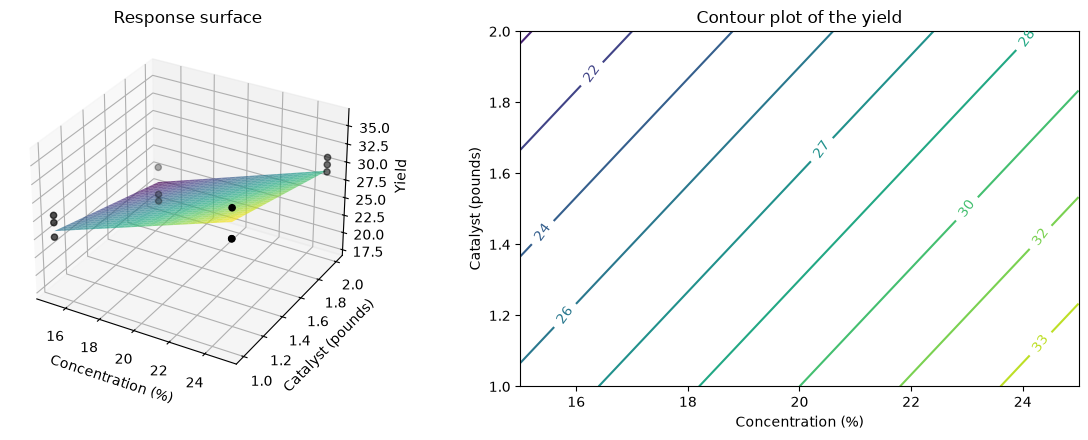

In [7]:
g1, g2 = np.meshgrid(np.linspace(15, 25, 51), np.linspace(1, 2, 51))
grid = pd.DataFrame({"conc": g1.ravel(), "cat": g2.ravel()})
z = m_nat.predict(grid).to_numpy().reshape(g1.shape)

fig = plt.figure(figsize=(12, 4.5))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot_surface(g1, g2, z, cmap="viridis", alpha=0.7)
ax1.scatter(chem["conc"], chem["cat"], chem["y"], color="k")
ax1.set(xlabel="Concentration (%)", ylabel="Catalyst (pounds)", zlabel="Yield", title="Response surface")
ax2 = fig.add_subplot(1, 2, 2)
cs = ax2.contour(g1, g2, z, levels=10, cmap="viridis")
ax2.clabel(cs, fmt="%.0f")
ax2.set(xlabel="Concentration (%)", ylabel="Catalyst (pounds)", title="Contour plot of the yield")
plt.tight_layout(); plt.show()

The first-order model is a plane: the contour lines are parallel straight lines. The yield increases towards high
concentration and low catalyst; the highest predicted yield inside the region is at $Conc = 25$ %, $Cat = 1$ pound.
Outside the region (and for possible curvature) the model says nothing.

### Model adequacy

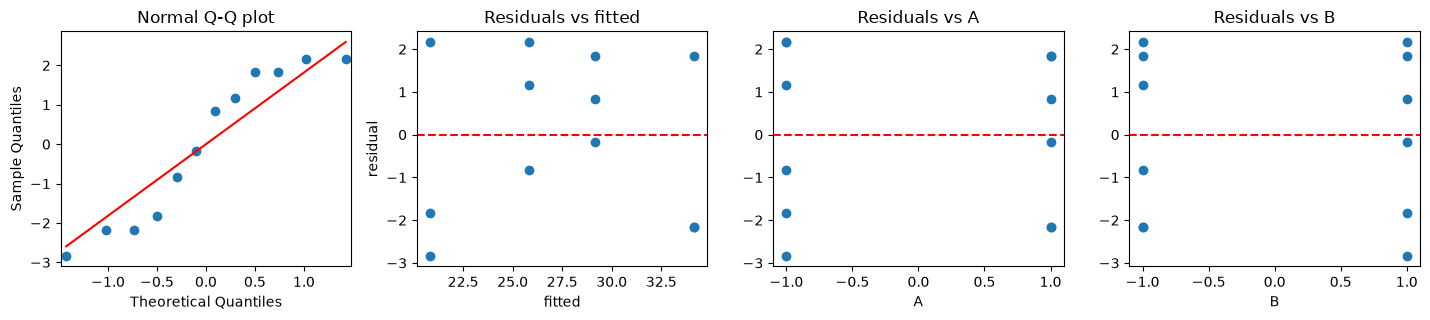

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.8817860960512489), pvalue=np.float64(0.09239123850830688))


In [8]:
residual_plots(m_red, chem, ["A", "B"])

## 2. Lecture example: plasma etch experiment ($2^3$ design)

Montgomery, Example 6.1: etch rate of silicon nitride (Å/min) in a single-wafer plasma etching tool. Factors: $A$ = gap between
the electrodes (0.8 and 1.2 cm), $B$ = C$_2$F$_6$ gas flow (125 and 200 SCCM), $C$ = RF power (275 and 325 W); $n = 2$ replicates.
The file has one row per treatment combination and the replicates in columns `R1`, `R2`; we reshape it to the long format.

In [9]:
plasma = pd.read_csv(URL + "plasma.txt", sep=r"\s+")
display(plasma.assign(total=plasma["R1"] + plasma["R2"]))

etch = plasma.melt(id_vars=["Run", "A", "B", "C"], value_vars=["R1", "R2"], var_name="rep", value_name="etch")
etch.head()

,Run,A,B,C,R1,R2,total
0,1,-1,-1,-1,550,604,1154
1,2,1,-1,-1,669,650,1319
2,3,-1,1,-1,633,601,1234
3,4,1,1,-1,642,635,1277
4,5,-1,-1,1,1037,1052,2089
5,6,1,-1,1,749,868,1617
6,7,-1,1,1,1075,1063,2138
7,8,1,1,1,729,860,1589


,Run,A,B,C,rep,etch
0,1,-1,-1,-1,R1,550
1,2,1,-1,-1,R1,669
2,3,-1,1,-1,R1,633
3,4,1,1,-1,R1,642
4,5,-1,-1,1,R1,1037


Note: the total of the treatment combination $bc$ is $1075 + 1063 = 2138$; the value 2178 printed in Table 6.4 of the book is a misprint.

### Effects from the table of signs

In [10]:
eff = effects_2k(etch, "etch", ["A", "B", "C"])
display(eff)

# the table of signs is the design matrix of the full coded model
full = smf.ols("etch ~ A * B * C", data=etch).fit()
X = pd.DataFrame(full.model.exog, columns=full.model.exog_names)
print(X.drop_duplicates().to_string(index=False))
print("X'X =\n", X.T @ X)

,contrast,effect,SS,coef
term,,,,
A,-813,-101.625,41310.5625,-50.8125
B,59,7.375,217.5625,3.6875
A:B,-199,-24.875,2475.0625,-12.4375
C,2449,306.125,374850.0625,153.0625
A:C,-1229,-153.625,94402.5625,-76.8125
B:C,-17,-2.125,18.0625,-1.0625
A:B:C,45,5.625,126.5625,2.8125


 Intercept    A    B  A:B    C  A:C  B:C  A:B:C
       1.0 -1.0 -1.0  1.0 -1.0  1.0  1.0   -1.0
       1.0  1.0 -1.0 -1.0 -1.0 -1.0  1.0    1.0
       1.0 -1.0  1.0 -1.0 -1.0  1.0 -1.0    1.0
       1.0  1.0  1.0  1.0 -1.0 -1.0 -1.0   -1.0
       1.0 -1.0 -1.0  1.0  1.0 -1.0 -1.0    1.0
       1.0  1.0 -1.0 -1.0  1.0  1.0 -1.0   -1.0
       1.0 -1.0  1.0 -1.0  1.0 -1.0  1.0   -1.0
       1.0  1.0  1.0  1.0  1.0  1.0  1.0    1.0
X'X =
            Intercept     A     B   A:B     C   A:C   B:C  A:B:C
Intercept       16.0   0.0   0.0   0.0   0.0   0.0   0.0    0.0
A                0.0  16.0   0.0   0.0   0.0   0.0   0.0    0.0
B                0.0   0.0  16.0   0.0   0.0   0.0   0.0    0.0
A:B              0.0   0.0   0.0  16.0   0.0   0.0   0.0    0.0
C                0.0   0.0   0.0   0.0  16.0   0.0   0.0    0.0
A:C              0.0   0.0   0.0   0.0   0.0  16.0   0.0    0.0
B:C              0.0   0.0   0.0   0.0   0.0   0.0  16.0    0.0
A:B:C            0.0   0.0   0.0   0.0   0.0   0.

The columns of the table of signs are orthogonal ($X^TX = 16\,I$). The large effects are $C$ (power, $+306$), $AC$ ($-154$)
and $A$ (gap, $-102$).

### ANOVA of the full model

In [11]:
sm.stats.anova_lm(full, typ=2)

,sum_sq,df,F,PR(>F)
A,41310.5625,1.0,18.339364,0.002679
B,217.5625,1.0,0.096584,0.763911
A:B,2475.0625,1.0,1.098776,0.325168
C,374850.0625,1.0,166.410505,0.000001
A:C,94402.5625,1.0,41.908965,0.000193
B:C,18.0625,1.0,0.008019,0.930849
A:B:C,126.5625,1.0,0.056186,0.818586
Residual,18020.5000,8.0,NaN,NaN


$A$, $C$ and $AC$ are significant; $B$ and all interactions with $B$ are not. With replicates, $MS_E = 2252.6$ (8 df) of the full
model is the **pure error**.

### Reduced model and lack of fit

In [12]:
red = smf.ols("etch ~ A * C", data=etch).fit()
display(sm.stats.anova_lm(red, typ=2))

# lack of fit of the reduced model = the dropped terms B, AB, BC, ABC, tested against the pure error
display(sm.stats.anova_lm(red, full))
print(red.summary().tables[1])
print(f"R2 = {red.rsquared:.4f}, adj. R2 = {red.rsquared_adj:.4f}  (full model: {full.rsquared:.4f}, {full.rsquared_adj:.4f})")

,sum_sq,df,F,PR(>F)
A,41310.5625,1.0,23.767029,3.816422e-04
C,374850.0625,1.0,215.660881,4.951261e-09
A:C,94402.5625,1.0,54.312222,8.620836e-06
Residual,20857.7500,12.0,NaN,NaN


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,12.0,20857.75,0.0,NaN,NaN,NaN
1,8.0,18020.50,4.0,2837.25,0.314891,0.860354


                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    776.0625     10.423     74.458      0.000     753.353     798.772
A            -50.8125     10.423     -4.875      0.000     -73.522     -28.103
C            153.0625     10.423     14.685      0.000     130.353     175.772
A:C          -76.8125     10.423     -7.370      0.000     -99.522     -54.103
R2 = 0.9608, adj. R2 = 0.9509  (full model: 0.9661, 0.9364)


The lack of fit is not significant ($F_0 = 0.31$, $p = 0.86$): the reduced model
$\hat y = 776.06 - 50.81\,x_1 + 153.06\,x_3 - 76.81\,x_1x_3$ is adequate. It explains $R^2 = 96.1$ % of the variability;
$R^2_{adj}$ increased from 0.936 to 0.951.

### Standard errors and confidence intervals of the effects

$V(\text{Effect}) = \sigma^2 / (n2^{k-2})$; the intervals of the effects are twice the intervals of the coded coefficients.

In [13]:
n, k = 2, 3
se_eff = np.sqrt(full.mse_resid / (n * 2**(k - 2)))
t = stats.t.ppf(0.975, full.df_resid)
print(f"se(effect) = {se_eff:.2f}, t = {t:.3f}, half-width = {t * se_eff:.2f}")

ci = 2 * full.conf_int().drop("Intercept")
ci.columns = ["lower", "upper"]
ci.insert(0, "effect", 2 * full.params.drop("Intercept"))
ci.round(2)

se(effect) = 23.73, t = 2.306, half-width = 54.72


,effect,lower,upper
A,-101.62,-156.35,-46.90
B,7.37,-47.35,62.10
A:B,-24.88,-79.60,29.85
C,306.13,251.40,360.85
A:C,-153.62,-208.35,-98.90
B:C,-2.12,-56.85,52.60
A:B:C,5.62,-49.10,60.35


Only the intervals of $A$, $C$ and $AC$ exclude zero, in agreement with the ANOVA.

### Main effects and interaction plots

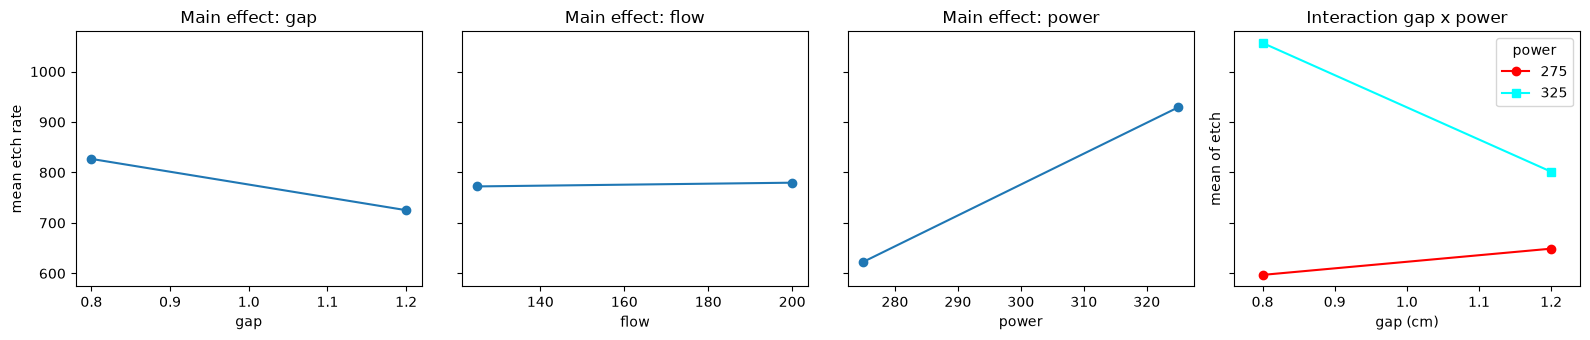

gap,0.8,1.2
power,,
275,597.00,649.0
325,1056.75,801.5


In [14]:
etch["gap"] = etch["A"].map({-1: 0.8, 1: 1.2})
etch["flow"] = etch["B"].map({-1: 125, 1: 200})
etch["power"] = etch["C"].map({-1: 275, 1: 325})

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, f in zip(axes[:3], ["gap", "flow", "power"]):
    means = etch.groupby(f)["etch"].mean()
    ax.plot(means.index, means.values, "o-")
    ax.set(xlabel=f, title=f"Main effect: {f}")
axes[0].set_ylabel("mean etch rate")
interaction_plot(etch["gap"], etch["power"], etch["etch"], markers=["o", "s"], ax=axes[3])
axes[3].set(xlabel="gap (cm)", title="Interaction gap x power")
plt.tight_layout(); plt.show()

# averages at the corners of the gap x power square
etch.pivot_table(index="power", columns="gap", values="etch", aggfunc="mean")

Because of the $AC$ interaction the main effect of the gap must be interpreted together with the power: at 275 W a larger gap
increases the etch rate slightly (597 to 649 Å/min), at 325 W it decreases it by about 255 Å/min (1056.75 to 801.5).
The main effect $A = -101.6$ is the average of these two simple effects.

### Response surface in natural units

Intercept   -5415.3750
gap          4354.6875
power          21.4850
gap:power     -15.3625
dtype: float64


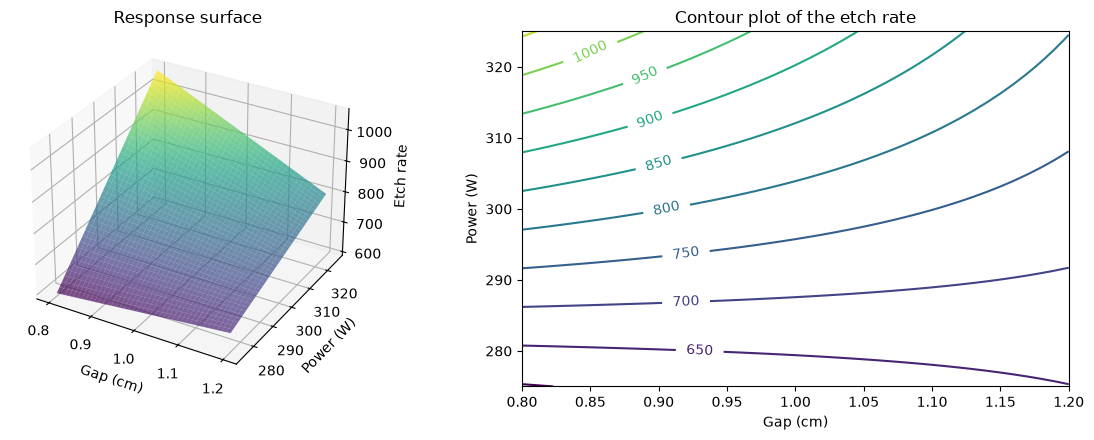

In [15]:
red_nat = smf.ols("etch ~ gap * power", data=etch).fit()
print(red_nat.params)

g1, g2 = np.meshgrid(np.linspace(0.8, 1.2, 41), np.linspace(275, 325, 41))
grid = pd.DataFrame({"gap": g1.ravel(), "power": g2.ravel()})
z = red_nat.predict(grid).to_numpy().reshape(g1.shape)

fig = plt.figure(figsize=(12, 4.5))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot_surface(g1, g2, z, cmap="viridis", alpha=0.7)
ax1.set(xlabel="Gap (cm)", ylabel="Power (W)", zlabel="Etch rate", title="Response surface")
ax2 = fig.add_subplot(1, 2, 2)
cs = ax2.contour(g1, g2, z, levels=np.arange(600, 1101, 50), cmap="viridis")
ax2.clabel(cs, fmt="%.0f")
ax2.set(xlabel="Gap (cm)", ylabel="Power (W)", title="Contour plot of the etch rate")
plt.tight_layout(); plt.show()

The interaction twists the plane, so the contour lines are curved. In natural units the coefficient of the gap is
$+4354.7$, although a larger gap decreases the etch rate everywhere in the region: with an interaction in the model it is the
slope at $Power = 0$ W. Interpret the coded model, use the natural one for predictions.

### Model adequacy

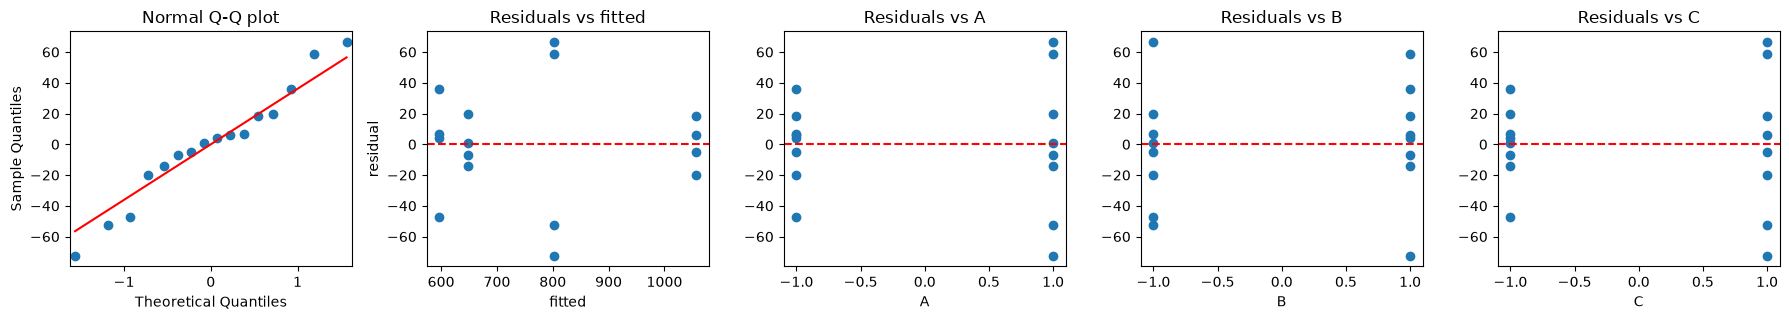

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9696763410381961), pvalue=np.float64(0.8333388290213518))


In [16]:
residual_plots(red, etch, ["A", "B", "C"])

The normal Q-Q plot is acceptable and the residuals versus $B$ (not in the model) show no effect of the gas flow. But the
residuals versus the fitted values have a much larger spread at the fitted value of about 800, i.e. at high gap and high power.
Let us compare the variances in the four gap $\times$ power cells.

In [17]:
cells_AC = [d["etch"].to_numpy(dtype=float) for _, d in etch.groupby(["A", "C"])]
print(etch.groupby(["A", "C"])["etch"].agg(["mean", "std"]).round(1))
print(stats.levene(*cells_AC))
print(stats.bartlett(*cells_AC))

         mean   std
A  C               
-1 -1   597.0  34.5
    1  1056.8  16.2
 1 -1   649.0  14.7
    1   801.5  72.7
LeveneResult(statistic=np.float64(11.222047088956753), pvalue=np.float64(0.0008497048286857502))
BartlettResult(statistic=np.float64(8.558062513256084), pvalue=np.float64(0.03578204658179196))


The standard deviation at high gap and high power is about 73 Å/min, two to five times larger than in the other cells
(Levene $p < 0.001$). The conclusions about the means are not in danger (the effects are huge compared with the noise), but the
equal-variance assumption is violated and the gap may also affect the **variability** of the process (a dispersion effect,
Montgomery, Section 6.5 and Supplemental Material S6.5). In practice this would be a further argument for the small gap.

## 3. Generating a randomized $2^k$ design

`design_2k()` returns the design in standard order with a random run order. Map the codes to the real levels and add an empty
column for the response; sort by `run` to get the run sheet.

In [18]:
plan = design_2k(3, n_rep=2, names="ABC", seed=2026)
plan["gap_cm"] = plan["A"].map({-1: 0.8, 1: 1.2})
plan["flow_sccm"] = plan["B"].map({-1: 125, 1: 200})
plan["power_W"] = plan["C"].map({-1: 275, 1: 325})
plan["etch"] = np.nan                                   # to be filled in during the experiment
plan.sort_values("run")

,std_order,A,B,C,rep,run,gap_cm,flow_sccm,power_W,etch
5,6,1,-1,1,1,1,1.2,125,325,NaN
3,4,1,1,-1,1,2,1.2,200,275,NaN
4,5,-1,-1,1,1,3,0.8,125,325,NaN
10,3,-1,1,-1,2,4,0.8,200,275,NaN
14,7,-1,1,1,2,5,0.8,200,325,NaN
11,4,1,1,-1,2,6,1.2,200,275,NaN
2,3,-1,1,-1,1,7,0.8,200,275,NaN
13,6,1,-1,1,2,8,1.2,125,325,NaN
8,1,-1,-1,-1,2,9,0.8,125,275,NaN
6,7,-1,1,1,1,10,0.8,200,325,NaN


If each replicate is run on a different day (or with a different batch of material), randomize the order within each
replicate separately and analyse the replicates as blocks (Lecture 7).

## Assignment

Work on the assignment in class (in pairs, if you like). Whatever you do not finish in class, finish at home as homework.

* Run the notebook above and make sure you understand each step.
* Solve the following problems from Montgomery, *Design and Analysis of Experiments* (8th edition): **6.5, 6.1, 6.2, 6.3,
  6.44 and 6.45**; Problem 6.8 is optional. Problems 6.1-6.3 and 6.44 use the same data.
* For every test state the hypotheses, report the test statistic, its $p$-value and your decision; check the assumptions with
  residual plots; end each problem with a conclusion in one or two sentences.
* Submit your solved notebook as a pull request into the `HW/` folder of the course repository, named
  `HW/01NAEX_Ex05_HW_<Surname>.ipynb` (see `HW/README.md`). **Deadline: Sunday 1 November 2026** (the next lecture is on 2 November).

### Problem 6.5: router vibration

A router is used to cut locating notches on a printed circuit board. The vibration level at the surface of the board as it is
cut is considered to be a major source of dimensional variation in the notches. Two factors are thought to influence
vibration: bit size ($A$: 1/16 and 1/8 in.) and cutting speed ($B$: 40 and 90 rpm). Four boards are cut at each set of
conditions; the response is vibration measured as the resultant vector of three accelerometers.

| $A$ | $B$ | Treatment combination | I | II | III | IV |
|---|---|---|---|---|---|---|
| $-$ | $-$ | (1) | 18.2 | 18.9 | 12.9 | 14.4 |
| $+$ | $-$ | $a$ | 27.2 | 24.0 | 22.4 | 22.5 |
| $-$ | $+$ | $b$ | 15.9 | 14.5 | 15.1 | 14.2 |
| $+$ | $+$ | $ab$ | 41.0 | 43.9 | 36.3 | 39.9 |

In [19]:
router = pd.DataFrame({
    "A": np.repeat([-1, 1, -1, 1], 4),
    "B": np.repeat([-1, -1, 1, 1], 4),
    "vibration": [18.2, 18.9, 12.9, 14.4, 27.2, 24.0, 22.4, 22.5,
                  15.9, 14.5, 15.1, 14.2, 41.0, 43.9, 36.3, 39.9]})
router.pivot_table(index="B", columns="A", values="vibration", aggfunc=list)

A,-1,1
B,,
-1,"[18.2, 18.9, 12.9, 14.4]","[27.2, 24.0, 22.4, 22.5]"
1,"[15.9, 14.5, 15.1, 14.2]","[41.0, 43.9, 36.3, 39.9]"


**Problem 6.5**

(a) Estimate the factor effects. Which effects appear to be large?

(b) Use the analysis of variance to confirm your conclusions for part (a) ($\alpha = 0.05$).

(c) Construct a normal probability plot of the residuals and plot the residuals versus the predicted vibration level.
Interpret these plots.

(d) Draw the $AB$ interaction plot and interpret it. What levels of bit size and speed would you recommend for routine operation?

**Solution.** Use independent errors with constant variance and approximate normality. All tests below use $\alpha=0.05$; each effect test has $H_0$: effect $=0$ versus $H_1$: effect $\ne0$. Randomized runs are needed for independence; the supplied treatment order is not a time order.

In [20]:
# (a) Effects are changes from the low to the high coded level.
display(effects_2k(router, "vibration", ["A", "B"]))
# (b) For each A, B and AB: H0 effect = 0; H1 effect != 0; alpha = .05.
router_model = smf.ols("vibration ~ A*B", router).fit()
router_anova = test_table(router_model)

,contrast,effect,SS,coef
term,,,,
A,133.1,16.6375,1107.225625,8.31875
B,60.3,7.5375,227.255625,3.76875
A:B,69.7,8.7125,303.630625,4.35625


,sum_sq,df,F,PR(>F),decision (alpha=.05)
A,1107.225625,1.0,185.251595,1.174669e-08,Reject H0
B,227.255625,1.0,38.022482,4.826292e-05,Reject H0
A:B,303.630625,1.0,50.800899,1.201078e-05,Reject H0
Residual,71.722500,12.0,NaN,NaN,


Error df = 12; MSE = 5.976875


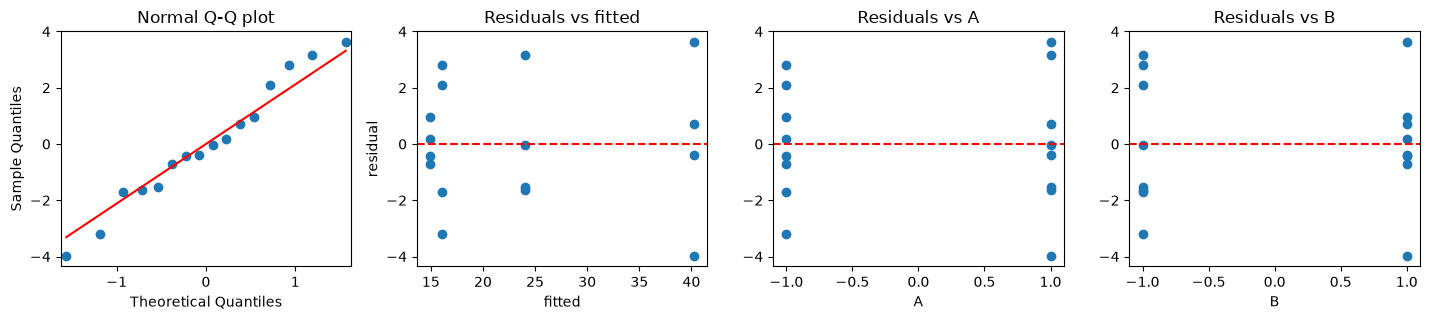

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9714201582416229), pvalue=np.float64(0.8610570052094948))
Shapiro decision: Do not reject H0


mean       std
A  B                   
-1 -1  16.100  2.908608
    1  14.925  0.750000
 1 -1  24.025  2.239606
    1  40.275  3.141523

In [21]:
# (c) Shapiro-Wilk: H0 normal errors; H1 nonnormal errors (diagnostic).
residual_plots(router_model, router, ["A", "B"])
print("Shapiro decision:", "Reject H0" if stats.shapiro(router_model.resid).pvalue < .05 else "Do not reject H0")
display(router.groupby(["A", "B"])["vibration"].agg(["mean", "std"]))

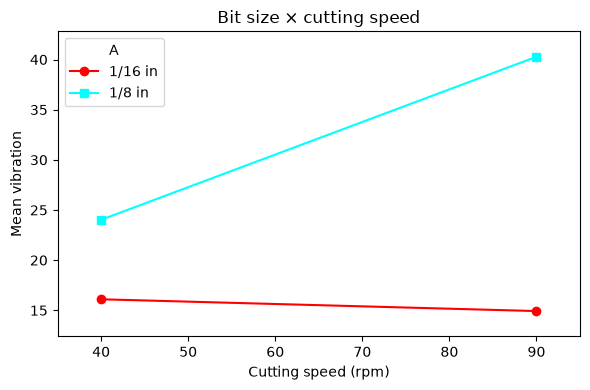

In [22]:
# (d) Actual factor levels in the interaction plot.
fig, ax = plt.subplots(figsize=(6, 4))
interaction_plot(router["B"].map({-1:40, 1:90}), router["A"].map({-1:"1/16 in", 1:"1/8 in"}),
                 router["vibration"], ax=ax, markers=["o", "s"])
ax.set(xlabel="Cutting speed (rpm)", ylabel="Mean vibration", title="Bit size × cutting speed")
plt.tight_layout(); plt.show()

**6.5 conclusions.** Effects are A = 16.6375, B = 7.5375 and AB = 8.7125. All are significant: respectively F(1,12) = 185.252, 38.022 and 50.801, with p = 1.17e-8, 4.83e-5 and 1.20e-5. The interaction matters: increasing speed changes mean vibration by −1.175 for the small bit but +16.250 for the large bit. To minimize vibration, choose the 1/16-inch bit and 90 rpm (observed mean 14.925); the two speeds with the small bit are close, so the exact speed preference merits confirmation.

Shapiro–Wilk W = 0.9714, p = 0.8611 does not reject normality. The residuals do not show marked skewness or a clear fitted-value trend, but spread is smaller for the small-bit/high-speed cell. With four replicates per cell, equal variance remains an approximation.

### Problem 6.8 (optional): virus growth

A bacteriologist is interested in the effects of two different culture media and two different times on the growth of a
particular virus. Six replicates of a $2^2$ design are run in random order.

| Time (h) | Culture medium 1 | Culture medium 2 |
|---|---|---|
| 12 | 21, 22, 23, 28, 20, 26 | 25, 26, 24, 25, 29, 27 |
| 18 | 37, 39, 38, 38, 35, 36 | 31, 34, 29, 33, 30, 35 |

In [23]:
virus = pd.DataFrame({
    "medium": np.repeat([1, 2, 1, 2], 6),
    "time": np.repeat([12, 12, 18, 18], 6),
    "growth": [21, 22, 23, 28, 20, 26, 25, 26, 24, 25, 29, 27,
               37, 39, 38, 38, 35, 36, 31, 34, 29, 33, 30, 35]})
virus.pivot_table(index="time", columns="medium", values="growth", aggfunc="mean")

medium,1,2
time,,
12,23.333333,26.0
18,37.166667,32.0


**Problem 6.8 (optional).** Analyse the data and draw appropriate conclusions. Is the effect of time the same for both media?
Analyse the residuals and comment on the model's adequacy.

**Solution:**

,contrast,effect,SS,coef
term,,,,
A,-15,-1.250000,9.375000,-0.625000
B,119,9.916667,590.041667,4.958333
A:B,-47,-3.916667,92.041667,-1.958333


,sum_sq,df,F,PR(>F),decision (alpha=.05)
A,9.375000,1.0,1.835237,1.906172e-01,Do not reject H0
B,590.041667,1.0,115.505710,9.290525e-10,Reject H0
A:B,92.041667,1.0,18.017945,3.969387e-04,Reject H0
Residual,102.166667,20.0,NaN,NaN,


Error df = 20; MSE = 5.108333


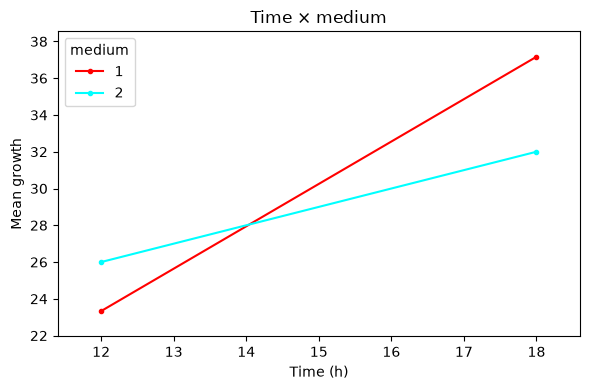

In [24]:
virus["A"] = virus["medium"].map({1:-1, 2:1})
virus["B"] = virus["time"].map({12:-1, 18:1})
# Each H0: named effect = 0; H1: nonzero.
virus_model = smf.ols("growth ~ A*B", virus).fit()
display(effects_2k(virus, "growth", ["A", "B"]))
test_table(virus_model)
fig, ax = plt.subplots(figsize=(6, 4))
interaction_plot(virus["time"], virus["medium"], virus["growth"], ax=ax)
ax.set(xlabel="Time (h)", ylabel="Mean growth", title="Time × medium")
plt.tight_layout(); plt.show()

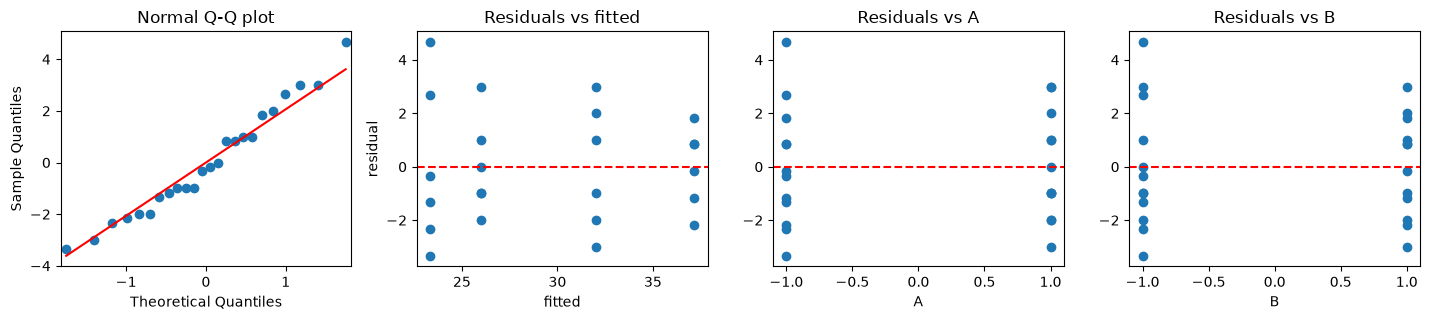

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.966156187433407), pvalue=np.float64(0.5736956734720472))
Shapiro decision: Do not reject H0


In [25]:
# Shapiro H0: normal errors; H1: nonnormal errors.
residual_plots(virus_model, virus, ["A", "B"])
print("Shapiro decision:", "Reject H0" if stats.shapiro(virus_model.resid).pvalue < .05 else "Do not reject H0")

**6.8 conclusions (optional).** Time and interaction are significant: F(1,20) = 115.506 (p = 9.29e-10) and 18.018 (p = 0.000397); medium averaged over time is not, F(1,20) = 1.835 (p = 0.1906). Time increases mean growth by 13.833 in medium 1 and 6.000 in medium 2, so its effect is not the same in both media. At 18 h, medium 1 gives the largest observed mean, 37.167. Shapiro W = 0.9662, p = 0.5737 does not reject normality; the residual plots show no strong distributional or variance warning. Independence relies on the stated randomized runs.

### Problem 6.1: tool life

An engineer is interested in the effects of cutting speed ($A$), tool geometry ($B$), and cutting angle ($C$) on the life
(in hours) of a machine tool. Two levels of each factor are chosen, and three replicates of a $2^3$ factorial design are run.
The results are as follows:

| $A$ | $B$ | $C$ | Treatment combination | I | II | III |
|---|---|---|---|---|---|---|
| $-$ | $-$ | $-$ | (1) | 22 | 31 | 25 |
| $+$ | $-$ | $-$ | $a$ | 32 | 43 | 29 |
| $-$ | $+$ | $-$ | $b$ | 35 | 34 | 50 |
| $+$ | $+$ | $-$ | $ab$ | 55 | 47 | 46 |
| $-$ | $-$ | $+$ | $c$ | 44 | 45 | 38 |
| $+$ | $-$ | $+$ | $ac$ | 40 | 37 | 36 |
| $-$ | $+$ | $+$ | $bc$ | 60 | 50 | 54 |
| $+$ | $+$ | $+$ | $abc$ | 39 | 41 | 47 |

In [26]:
tool = pd.read_csv(URL + "Problem_6_1.txt", sep=";")
tool.columns = ["A", "B", "C", "life"]        # cutting speed, tool geometry, cutting angle; life in hours
tool.pivot_table(index=["C", "B"], columns="A", values="life", aggfunc=list)

A                -1             1
C  B                             
-1 -1  [22, 31, 25]  [32, 43, 29]
    1  [35, 34, 50]  [55, 47, 46]
 1 -1  [44, 45, 38]  [40, 37, 36]
    1  [60, 50, 54]  [39, 41, 47]

**Problem 6.1**

(a) Estimate the factor effects. Which effects appear to be large?

(b) Use the analysis of variance to confirm your conclusions for part (a).

(c) Write down a regression model for predicting tool life (in hours) based on the results of this experiment.

(d) Analyze the residuals. Are there any obvious problems?

(e) On the basis of an analysis of main effect and interaction plots, what coded factor levels of $A$, $B$, and $C$ would
you recommend using?

**Solution:**

In [27]:
# (a, b) H0 for each term: its effect is zero; H1: nonzero, alpha=.05.
tool_effects = effects_2k(tool, "life", ["A", "B", "C"])
display(tool_effects)
tool_full = smf.ols("life ~ A*B*C", tool).fit()
test_table(tool_full)
# (c) Retain A for hierarchy because AC is significant.
tool_hier = smf.ols("life ~ A+B+C+A:C", tool).fit()
display(tool_hier.params.rename("Coded regression coefficient"))
# H0: AB=BC=ABC=0 (reduced model adequate); H1: at least one nonzero.
lof = sm.stats.anova_lm(tool_hier, tool_full)
display(lof)
print("Lack-of-fit decision:", "Reject H0" if lof.iloc[1]["Pr(>F)"] < .05 else "Do not reject H0")

,contrast,effect,SS,coef
term,,,,
A,4,0.333333,0.666667,0.166667
B,136,11.333333,770.666667,5.666667
A:B,-20,-1.666667,16.666667,-0.833333
C,82,6.833333,280.166667,3.416667
A:C,-106,-8.833333,468.166667,-4.416667
B:C,-34,-2.833333,48.166667,-1.416667
A:B:C,-26,-2.166667,28.166667,-1.083333


,sum_sq,df,F,PR(>F),decision (alpha=.05)
A,0.666667,1.0,0.022099,0.883680,Do not reject H0
B,770.666667,1.0,25.546961,0.000117,Reject H0
A:B,16.666667,1.0,0.552486,0.468078,Do not reject H0
C,280.166667,1.0,9.287293,0.007679,Reject H0
A:C,468.166667,1.0,15.519337,0.001172,Reject H0
B:C,48.166667,1.0,1.596685,0.224475,Do not reject H0
A:B:C,28.166667,1.0,0.933702,0.348282,Do not reject H0
Residual,482.666667,16.0,NaN,NaN,


Error df = 16; MSE = 30.166667


Intercept    40.833333
A             0.166667
B             5.666667
C             3.416667
A:C          -4.416667
Name: Coded regression coefficient, dtype: float64

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,19.0,575.666667,0.0,NaN,NaN,NaN
1,16.0,482.666667,3.0,93.0,1.027624,0.406692


Lack-of-fit decision: Do not reject H0


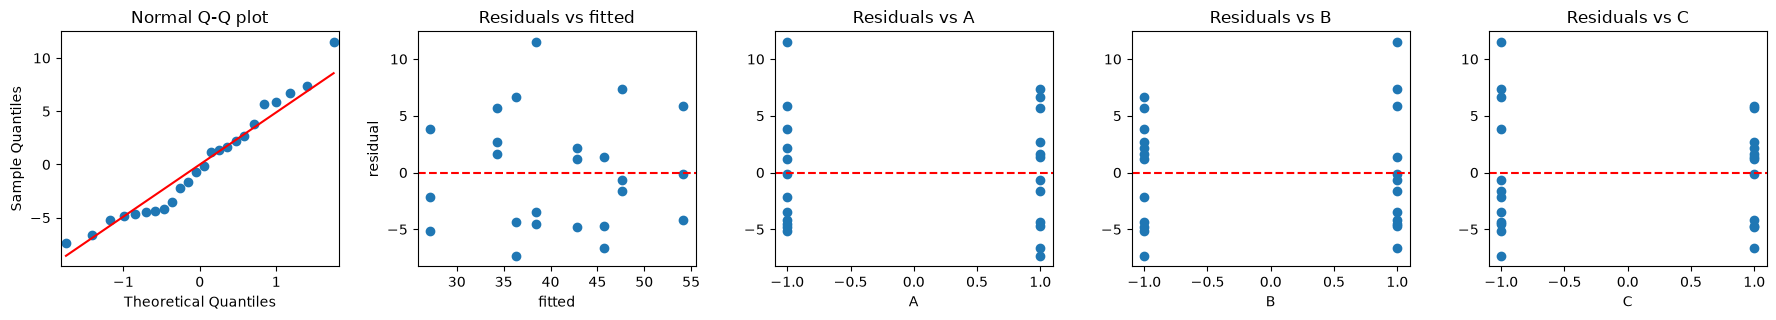

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.953001502488771), pvalue=np.float64(0.3142911274142699))
Shapiro decision: Do not reject H0


mean       std
A  B  C                      
-1 -1 -1  26.000000  4.582576
       1  42.333333  3.785939
    1 -1  39.666667  8.962886
       1  54.666667  5.033223
 1 -1 -1  34.666667  7.371115
       1  37.666667  2.081666
    1 -1  49.333333  4.932883
       1  42.333333  4.163332

In [28]:
# (d) Shapiro H0: normal errors; H1: nonnormal errors.
residual_plots(tool_hier, tool, ["A", "B", "C"])
print("Shapiro decision:", "Reject H0" if stats.shapiro(tool_hier.resid).pvalue < .05 else "Do not reject H0")
display(tool.groupby(["A", "B", "C"])["life"].agg(["mean", "std"]))

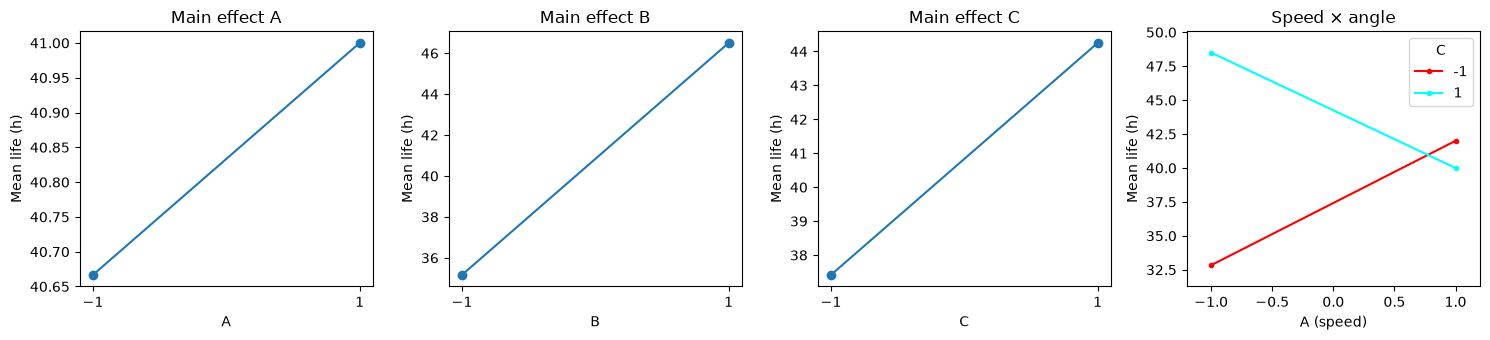

,A,B,C,predicted life
6,-1,1,1,54.166667
3,1,1,-1,47.666667
7,1,1,1,45.666667
4,-1,-1,1,42.833333
2,-1,1,-1,38.500000
1,1,-1,-1,36.333333
5,1,-1,1,34.333333
0,-1,-1,-1,27.166667


In [29]:
# (e) Main effects and the important interaction.
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, factor in zip(axes[:3], ["A", "B", "C"]):
    means = tool.groupby(factor)["life"].mean()
    ax.plot(means.index, means.values, "o-")
    ax.set(xlabel=factor, ylabel="Mean life (h)", title=f"Main effect {factor}", xticks=[-1,1])
interaction_plot(tool["A"], tool["C"], tool["life"], ax=axes[3])
axes[3].set(title="Speed × angle", xlabel="A (speed)", ylabel="Mean life (h)")
plt.tight_layout(); plt.show()
corners = design_2k(3)[["A", "B", "C"]]
corners["predicted life"] = tool_hier.predict(corners)
display(corners.sort_values("predicted life", ascending=False))

**6.1 conclusions.** The large effects are B = 11.333, C = 6.833 and AC = −8.833 hours. Their F(1,16) statistics are 25.547, 9.287 and 15.519 (p = 0.000117, 0.007679 and 0.001172). A, AB, BC and ABC are not significant. The hierarchical reduced model is

$$\widehat{life}=40.8333+0.1667A+5.6667B+3.4167C-4.4167AC.$$

Keep A despite its nonsignificance because it is part of AC. The lack-of-fit test jointly removes AB, BC and ABC; its output above does not reject the reduced model. Shapiro W = 0.9530, p = 0.3143 does not reject normality. Residuals have some unequal cell spreads and a few larger positive values, but no obvious severe departure; only three replicates per cell limit diagnosis, and independence requires randomized runs.

Choose A = −1, B = +1, C = +1: predicted life is 54.167 h. The near-zero average A effect hides a substantial interaction; at high angle, lower speed is preferable. These are coded settings, since natural factor levels were not supplied.

**Problem 6.2.** Reconsider part (c) of Problem 6.1. Use the regression model to generate response surface and contour plots
of the tool life response. Interpret these plots. Do they provide insight regarding the desirable operating conditions for
this process? (The problem gives no natural levels, so draw the plots in the coded variables; with three factors fix the
third one at $-1$ and at $+1$.)

**Solution:**

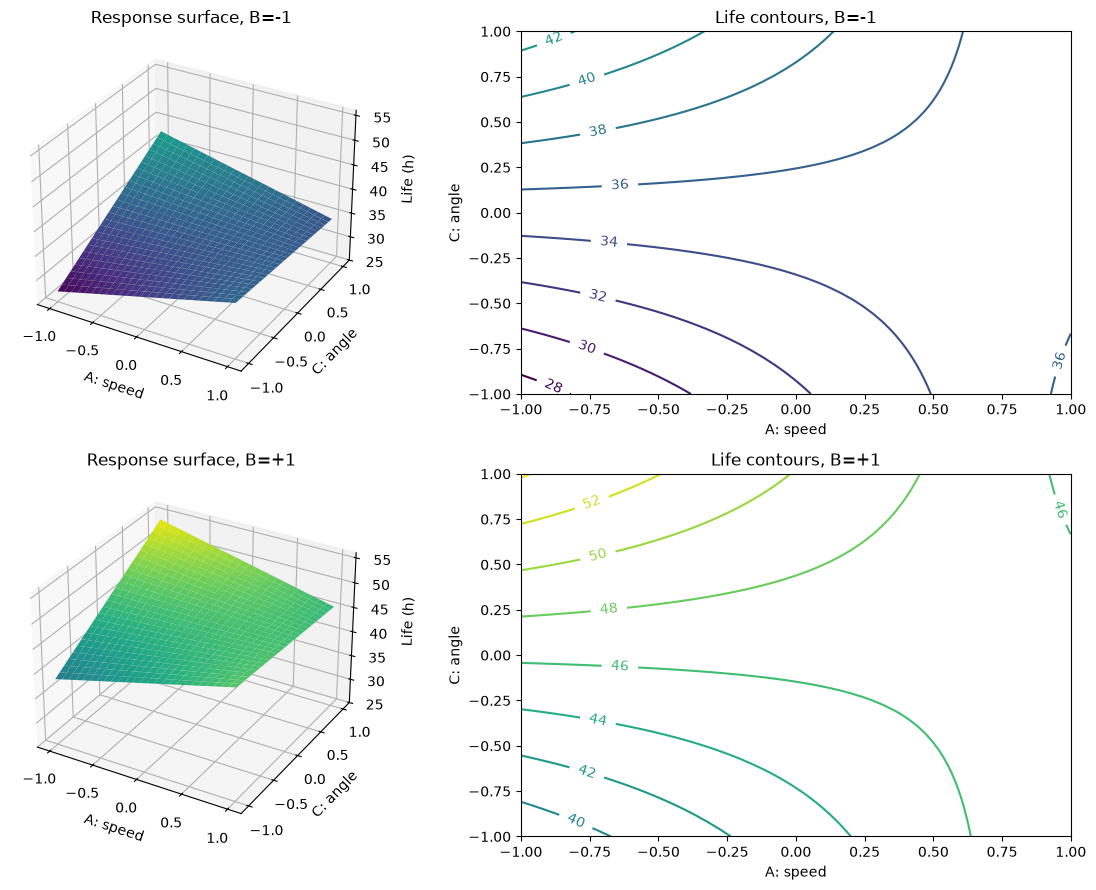

In [30]:
# Fix geometry B at each level and plot the interacting factors A and C.
gA, gC = np.meshgrid(np.linspace(-1, 1, 51), np.linspace(-1, 1, 51))
fig = plt.figure(figsize=(12, 9))
for row, b in enumerate([-1, 1]):
    grid = pd.DataFrame({"A":gA.ravel(), "B":b, "C":gC.ravel()})
    z = tool_hier.predict(grid).to_numpy().reshape(gA.shape)
    ax = fig.add_subplot(2, 2, 2*row+1, projection="3d")
    ax.plot_surface(gA, gC, z, cmap="viridis", vmin=27, vmax=55)
    ax.set(xlabel="A: speed", ylabel="C: angle", zlabel="Life (h)", title=f"Response surface, B={b:+d}", zlim=(25,56))
    ax = fig.add_subplot(2, 2, 2*row+2)
    cs = ax.contour(gA, gC, z, levels=np.arange(28, 56, 2), cmap="viridis")
    ax.clabel(cs, fmt="%.0f")
    ax.set(xlabel="A: speed", ylabel="C: angle", title=f"Life contours, B={b:+d}")
plt.tight_layout(); plt.show()

In [31]:
# Slopes show why the best speed depends on cutting angle.
for c in [-1, 1]:
    print(f"At C={c:+d}: slope in A = {tool_hier.params['A'] + c*tool_hier.params['A:C']:.3f} h per coded unit")
print("Increasing B from -1 to +1 adds", 2*tool_hier.params["B"], "hours everywhere in this model.")

At C=-1: slope in A = 4.583 h per coded unit
At C=+1: slope in A = -4.250 h per coded unit
Increasing B from -1 to +1 adds 11.333333333333332 hours everywhere in this model.


**6.2 conclusion.** The AC term twists the response surface: the speed slope is +4.583 at C = −1 and −4.250 at C = +1. Increasing geometry B raises the entire surface by 11.333 h. Within the tested cube the largest fitted life occurs at (−1,+1,+1); the contours support this recommendation. These two-level data cannot establish curvature or an optimum outside the experimental region.

**Problem 6.3.** Find the standard error of the factor effects and approximate 95 percent confidence limits for the factor
effects in Problem 6.1. Do the results of this analysis agree with the conclusions from the analysis of variance?

**Solution:**

In [32]:
# Use pure error from the full replicated factorial model.
k, n_rep = 3, 3
se_effect = np.sqrt(tool_full.mse_resid / (n_rep * 2**(k-2)))
tcrit = stats.t.ppf(.975, tool_full.df_resid)
print(f"SE(effect) = {se_effect:.6f}; df = {tool_full.df_resid:g}; t critical = {tcrit:.6f}")
ci_effects = tool_effects[["effect"]].copy()
ci_effects["SE"] = se_effect
ci_effects["lower 95%"] = ci_effects["effect"] - tcrit*se_effect
ci_effects["upper 95%"] = ci_effects["effect"] + tcrit*se_effect
ci_effects["excludes zero"] = ci_effects["lower 95%"] * ci_effects["upper 95%"] > 0
display(ci_effects)

SE(effect) = 2.242271; df = 16; t critical = 2.119905


,effect,SE,lower 95%,upper 95%,excludes zero
term,,,,,
A,0.333333,2.242271,-4.420068,5.086735,False
B,11.333333,2.242271,6.579932,16.086735,True
A:B,-1.666667,2.242271,-6.420068,3.086735,False
C,6.833333,2.242271,2.079932,11.586735,True
A:C,-8.833333,2.242271,-13.586735,-4.079932,True
B:C,-2.833333,2.242271,-7.586735,1.920068,False
A:B:C,-2.166667,2.242271,-6.920068,2.586735,False


In [33]:
# Check agreement of each two-sided t test with its 1-df ANOVA F test.
# Each H0: effect = 0, H1: effect != 0.
ci_effects["t"] = ci_effects["effect"] / se_effect
ci_effects["p"] = 2*stats.t.sf(abs(ci_effects["t"]), tool_full.df_resid)
ci_effects["decision"] = np.where(ci_effects["p"] < .05, "Reject H0", "Do not reject H0")
display(ci_effects[["t", "p", "decision"]])
assert np.allclose(ci_effects["t"]**2, sm.stats.anova_lm(tool_full, typ=2).loc[ci_effects.index, "F"])

,t,p,decision
term,,,
A,0.148659,0.883680,Do not reject H0
B,5.054400,0.000117,Reject H0
A:B,-0.743294,0.468078,Do not reject H0
C,3.047506,0.007679,Reject H0
A:C,-3.939459,0.001172,Reject H0
B:C,-1.263600,0.224475,Do not reject H0
A:B:C,-0.966282,0.348282,Do not reject H0


**6.3 conclusion.** Pure-error MSE = 30.1667 on 16 df gives SE(effect) = 2.24227 h and a 95% half-width of approximately 4.753 h. Only B, C and AC have intervals excluding zero, exactly agreeing with their ANOVA tests because F = t² for each one-degree-of-freedom effect. These are individual 95% intervals, not simultaneous coverage for all seven effects.

**Problem 6.44: hierarchical models.** Several times we have used the hierarchy principle in selecting a model; that is,
we have included nonsignificant lower order terms in a model because they were factors involved in significant higher order
terms. Hierarchy is certainly not an absolute principle that must be followed in all cases. To illustrate, consider the
model resulting from Problem 6.1, which required that a nonsignificant main effect be included to achieve hierarchy. Using the
data from Problem 6.1:

(a) Fit both the hierarchical and the nonhierarchical models.

(b) Calculate the PRESS statistic, the adjusted $R^2$, and the mean square error for both models.
(PRESS $= \sum_i \left(e_i / (1 - h_{ii})\right)^2$; the leverages $h_{ii}$ are in `model.get_influence().hat_matrix_diag`.)

(c) Find a 95 percent confidence interval on the estimate of the mean response at a cube corner
($x_1 = x_2 = x_3 = \pm 1$). Hint: `model.get_prediction(new_data).summary_frame()`; compare with
$V(\hat y) = \sigma^2 \sum_j x_j^2 / (n2^k)$ (sum over the terms in the model, including the intercept).

(d) Based on the analyses you have conducted, which model do you prefer?

**Solution:**

In [34]:
tool_nonhier = smf.ols("life ~ B+C+A:C", tool).fit()
models = {"Hierarchical":tool_hier, "Nonhierarchical":tool_nonhier}
comparison = []
for name, model in models.items():
    display(model.params.rename(name))
    h = model.get_influence().hat_matrix_diag
    comparison.append({"model":name, "parameters":len(model.params), "error df":model.df_resid,
                       "PRESS":np.sum((model.resid/(1-h))**2),
                       "adjusted R2":model.rsquared_adj, "MSE":model.mse_resid})
display(pd.DataFrame(comparison).set_index("model"))

Intercept    40.833333
A             0.166667
B             5.666667
C             3.416667
A:C          -4.416667
Name: Hierarchical, dtype: float64

Intercept    40.833333
B             5.666667
C             3.416667
A:C          -4.416667
Name: Nonhierarchical, dtype: float64

,parameters,error df,PRESS,adjusted R2,MSE
model,,,,,
Hierarchical,5,19.0,918.515235,0.667423,30.298246
Nonhierarchical,4,20.0,829.920000,0.683686,28.816667


In [35]:
# Pointwise confidence intervals for the MEAN, not prediction intervals for a new run.
corner_ci = []
for name, model in models.items():
    pred = model.get_prediction(corners).summary_frame(alpha=.05)
    result = corners[["A", "B", "C"]].copy()
    result["model"] = name
    for col in ["mean", "mean_se", "mean_ci_lower", "mean_ci_upper"]:
        result[col] = pred[col].to_numpy()
    corner_ci.append(result)
    # All model terms have squared value 1 at a cube corner.
    variance = model.mse_resid * len(model.params) / len(tool)
    assert np.allclose(pred["mean_se"]**2, variance)
    print(f"{name}: corner variance={variance:.6f}, CI half-width={stats.t.ppf(.975,model.df_resid)*np.sqrt(variance):.6f}")
display(pd.concat(corner_ci, ignore_index=True))

Hierarchical: corner variance=6.312135, CI half-width=5.258506
Nonhierarchical: corner variance=4.802778, CI half-width=4.571439


,A,B,C,model,mean,mean_se,mean_ci_lower,mean_ci_upper
0,-1,-1,-1,Hierarchical,27.166667,2.512396,21.908161,32.425172
1,1,-1,-1,Hierarchical,36.333333,2.512396,31.074828,41.591839
2,-1,1,-1,Hierarchical,38.500000,2.512396,33.241494,43.758506
3,1,1,-1,Hierarchical,47.666667,2.512396,42.408161,52.925172
4,-1,-1,1,Hierarchical,42.833333,2.512396,37.574828,48.091839
5,1,-1,1,Hierarchical,34.333333,2.512396,29.074828,39.591839
6,-1,1,1,Hierarchical,54.166667,2.512396,48.908161,59.425172
7,1,1,1,Hierarchical,45.666667,2.512396,40.408161,50.925172
8,-1,-1,-1,Nonhierarchical,27.333333,2.191524,22.761894,31.904772
9,1,-1,-1,Nonhierarchical,36.166667,2.191524,31.595228,40.738106


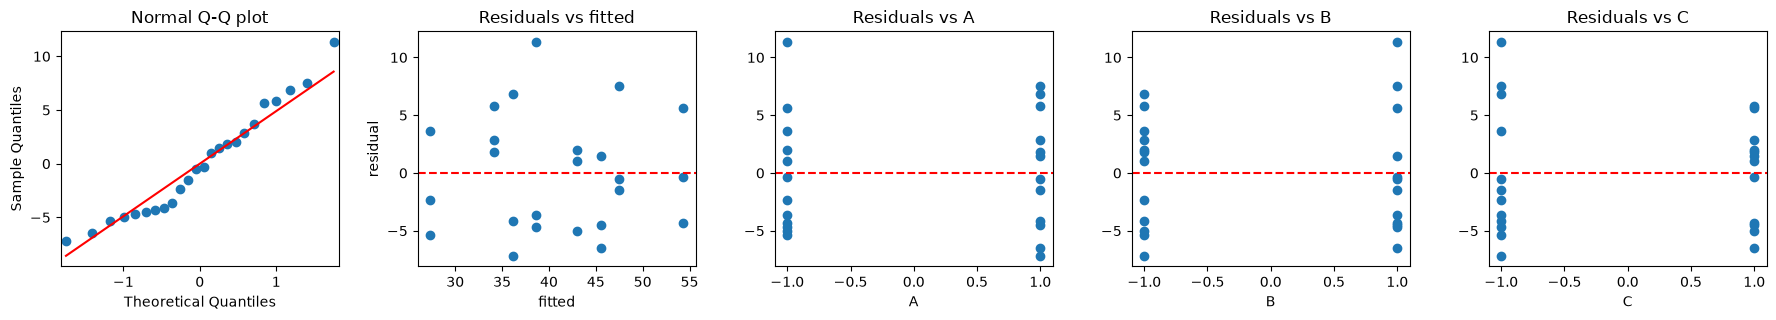

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9502462256887675), pvalue=np.float64(0.27429153777063764))
Shapiro decision: Do not reject H0


In [36]:
# Diagnostics for the alternative model; same Shapiro hypotheses as above.
residual_plots(tool_nonhier, tool, ["A", "B", "C"])
print("Shapiro decision:", "Reject H0" if stats.shapiro(tool_nonhier.resid).pvalue < .05 else "Do not reject H0")

**6.44 conclusion.** The hierarchical model has PRESS = 918.515, adjusted R² = 0.66742 and MSE = 30.29825 (19 error df). Removing A gives PRESS = 829.920, adjusted R² = 0.68369 and MSE = 28.81667 (20 error df). At the recommended corner (−1,+1,+1), the models predict 54.167 and 54.333 h; the displayed intervals use the mean-response standard error, not the larger individual-response prediction error. At every corner the variance is MSE × p/24 with p = 5 or 4 model coefficients.

For prediction within this coded region, I prefer the nonhierarchical model: it has lower PRESS and MSE, higher adjusted R², and narrower mean-response intervals. Its diagnostics are similar (Shapiro W = 0.9502, p = 0.2743, no rejection). The improvement is modest and the selected-model intervals ignore model-selection uncertainty; for interpretation or recoding of the factors, hierarchy remains attractive because dropping A while retaining AC depends on the chosen origin.

**Problem 6.45.** Suppose that you want to run a $2^3$ factorial design. The variance of an individual observation is
expected to be about 4. Suppose that you want the length of a 95 percent confidence interval on any effect to be less than or
equal to 1.5. How many replicates of the design do you need to run? (Use the $t$ quantile with the error degrees of freedom
of the full model, $2^k(n-1)$, and compare with the normal approximation.)

**Solution:**

In [37]:
# Var(effect) = sigma^2 / (n*2^(k-2)); full-model error df = 2^k*(n-1).
sigma2, k, max_length = 4, 3, 1.5

def effect_ci_length(n):
    return 2*stats.t.ppf(.975, 2**k*(n-1))*np.sqrt(sigma2/(n*2**(k-2)))

n_required = next(n for n in range(2, 10000) if effect_ci_length(n) <= max_length)
display(pd.DataFrame([{"replicates":n, "total runs":2**k*n,
                       "error df":2**k*(n-1), "95% CI length":effect_ci_length(n)}
                      for n in [n_required-1, n_required]]))
print(f"Required: {n_required} replicates of the complete design, {2**k*n_required} runs.")

,replicates,total runs,error df,95% CI length
0,13,104,96,1.557150
1,14,112,104,1.499035


Required: 14 replicates of the complete design, 112 runs.


In [38]:
zcrit = stats.norm.ppf(.975)
n_normal_real = 4*zcrit**2*sigma2 / (2**(k-2)*max_length**2)
n_normal = int(np.ceil(n_normal_real))
print(f"Normal approximation: n >= {n_normal_real:.6f}, rounded up to {n_normal} replicates.")
assert effect_ci_length(n_required) <= max_length < effect_ci_length(n_required-1)

Normal approximation: n >= 13.658520, rounded up to 14 replicates.


**6.45 conclusion.** Fourteen replicates of the full design are needed, giving 112 runs. The normal approximation also rounds up to 14 replicates; checking the t-based lengths at 13 and 14 proves the minimum. This planning calculation treats the anticipated variance 4 as the future MSE; an actual estimated variance may yield a different interval length.